# Trabajo Final Machine Learning

## Ejercicio 3: Clustering - Wholesale Customers

**Grupo:** A

**Integrantes:**
Matías Diaz - Melina Yamgotchian - Noelia García - Federico Otte


## Índice

1. Metadata
2. Análisis exploratorio de datos (EDA)
3. Preparación de datos
4. Modelo K-Means
5. Modelo DBSCAN
6. Comparación de resultados
7. Identificación de perfiles de clientes
8. Interpretación final

In [1]:
# Librerías para manipulación de datos
import pandas as pd
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

# Usar el archivo local si está disponible. En otro caso, descargar el ZIP oficial.
archivo_datos = Path("Wholesale customers data.csv")
url_datos = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"
if archivo_datos.is_file():
    df = pd.read_csv(archivo_datos)
else:
    df = pd.read_csv(url_datos, compression="zip")

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 1. Metadata y descripción del dataset

Para realizar el ejercicio de clustering se utilizó el dataset **Wholesale Customers**, obtenido del repositorio UCI Machine Learning Repository.

El conjunto de datos contiene información de 440 clientes mayoristas y registra sus gastos anuales en diferentes categorías de productos.

Está compuesto por 8 variables:

- **Channel:** canal de venta del cliente.
- **Region:** región geográfica.
- **Fresh:** gasto anual en productos frescos.
- **Milk:** gasto anual en productos lácteos.
- **Grocery:** gasto anual en productos de almacén.
- **Frozen:** gasto anual en productos congelados.
- **Detergents_Paper:** gasto anual en detergentes y artículos de papel.
- **Delicassen:** gasto anual en productos delicatessen.

El objetivo del ejercicio es aplicar técnicas de aprendizaje no supervisado para identificar posibles grupos de clientes con patrones de consumo similares, utilizando los algoritmos K-Means y DBSCAN.

In [3]:
# Conocer la cantidad de filas y columnas
df.shape

(440, 8)

In [4]:
# Obtener información general del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
# Obtener estadísticas descriptivas
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### 2. Análisis exploratorio de datos (EDA)

En esta etapa se realizó un análisis inicial del conjunto de datos para comprender su estructura y características.

Se analizaron las dimensiones del dataset, los tipos de variables y las principales estadísticas descriptivas.

Este análisis permite conocer el comportamiento general de los gastos de los clientes y detectar posibles particularidades que deban considerarse antes de aplicar los modelos de clustering.

In [6]:
# Verificar si existen valores faltantes
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [7]:
# Verificar si existen registros duplicados
df.duplicated().sum()

np.int64(0)

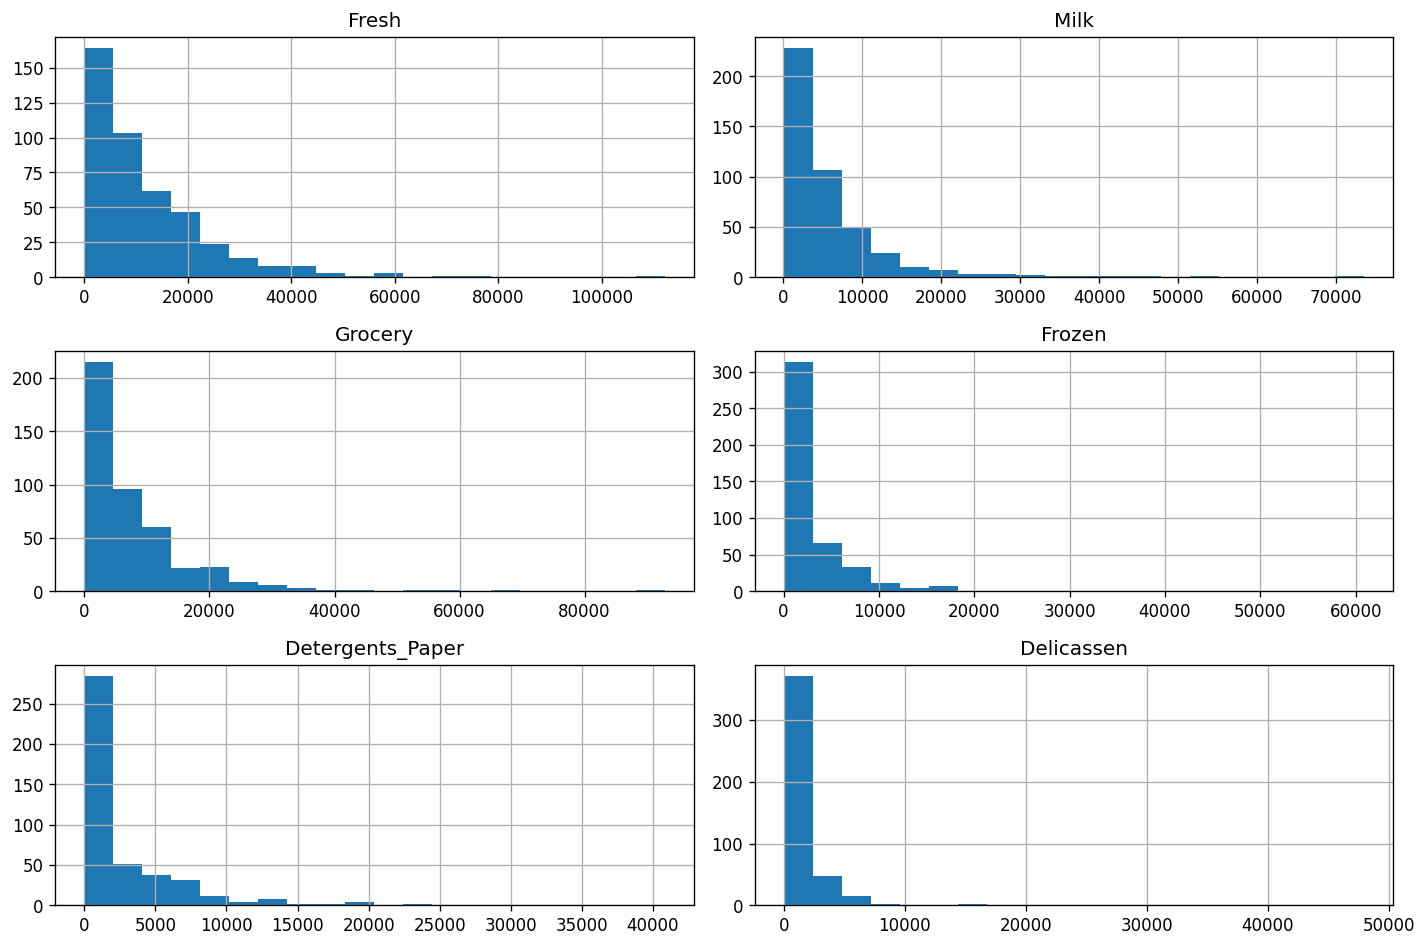

In [8]:
# Visualizar la distribución de los gastos de los clientes

variables_gasto = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper', 'Delicassen'
]

df[variables_gasto].hist(figsize=(12, 8), bins=20)

plt.tight_layout()
plt.show()

### Interpretación del análisis exploratorio

A partir del análisis realizado se obtuvieron las siguientes observaciones:

- No se identificaron valores faltantes en ninguna de las variables.
- No se encontraron registros duplicados.
- Las variables correspondientes a los gastos de los clientes presentan distribuciones asimétricas hacia la derecha. Esto indica que existen diferencias importantes en los niveles de gasto entre los clientes y que algunos presentan valores considerablemente superiores al resto.

Estas características deben tenerse en cuenta durante la preparación de los datos, ya que las diferencias de escala y la presencia de valores extremos pueden influir en los resultados de los algoritmos de clustering.

## 3. Preparación de los datos

Para aplicar los algoritmos de clustering se seleccionaron las seis variables relacionadas con los gastos anuales de los clientes.

Se excluyeron inicialmente las variables Channel y Region, ya que el objetivo es identificar agrupamientos basados en los patrones de consumo.

Además, debido a la asimetría observada en las distribuciones, se aplicará una transformación logarítmica y posteriormente una estandarización de las variables.

In [9]:
# Seleccionar las variables de gasto
variables_gasto = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper', 'Delicassen'
]

X = df[variables_gasto].copy()

# Aplicar transformación logarítmica
X_log = np.log1p(X)

# Visualizar los primeros registros transformados
X_log.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


In [10]:
# Importar StandardScaler
from sklearn.preprocessing import StandardScaler

# Estandarizar las variables
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# Convertir nuevamente a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=variables_gasto)

# Visualizar los primeros registros
X_scaled.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


### Interpretación de la preparación de datos

Se seleccionaron las seis variables correspondientes a los gastos de los clientes y se aplicó una transformación logarítmica para reducir la asimetría de sus distribuciones.

Posteriormente, se utilizó StandardScaler para estandarizar las variables, de manera que todas tengan una escala comparable.

Como resultado, se obtuvo un conjunto de datos preparado para aplicar los algoritmos de clustering, evitando que las diferencias en las magnitudes de los gastos influyan desproporcionadamente en el cálculo de distancias.

## 4. Modelo K-Means

K-Means es un algoritmo de aprendizaje no supervisado que permite agrupar clientes según la similitud de sus patrones de gasto.

Para determinar la cantidad adecuada de clusters, se evaluarán diferentes valores de K utilizando el método del codo y el coeficiente Silhouette.

In [11]:
# Importar las herramientas necesarias
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluar diferentes cantidades de clusters
resultados = []

for k in range(2, 11):

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    etiquetas = kmeans.fit_predict(X_scaled)

    inercia = kmeans.inertia_
    silhouette = silhouette_score(X_scaled, etiquetas)

    resultados.append([k, inercia, silhouette])

# Mostrar los resultados
resultados_df = pd.DataFrame(
    resultados,
    columns=['Cantidad de clusters', 'Inercia', 'Silhouette']
)

resultados_df

,Cantidad de clusters,Inercia,Silhouette
0,2,1844.064069,0.290328
1,3,1553.421327,0.259416
2,4,1386.862741,0.188495
3,5,1266.149362,0.191585
4,6,1174.758633,0.200887
5,7,1086.358700,0.195780
6,8,1028.486217,0.185175
7,9,973.141483,0.196501
8,10,931.998464,0.190523


### Evaluación de diferentes cantidades de clusters

Para determinar la cantidad adecuada de grupos, se entrenaron diferentes modelos K-Means utilizando valores de K entre 2 y 10.

Para cada modelo se calcularon dos métricas:

- **Inercia:** mide la suma de las distancias cuadráticas entre cada observación y el centro de su cluster. Valores menores indican grupos más compactos.
- **Coeficiente Silhouette:** evalúa la cohesión de los grupos y su separación respecto a los demás. Sus valores oscilan entre -1 y 1, siendo los valores más cercanos a 1 los que indican una mejor separación.

### Análisis de los resultados

A partir de los resultados obtenidos se observa que la inercia disminuye progresivamente a medida que aumenta la cantidad de clusters. Esto es esperable, ya que al incrementar el número de grupos los clientes pueden distribuirse en conjuntos más pequeños y homogéneos.

En cuanto al coeficiente Silhouette, el valor más alto se obtuvo utilizando 2 clusters, con un resultado de 0.2903. Esto indica que, entre las alternativas evaluadas, K=2 presenta la mejor separación relativa entre los grupos.

Sin embargo, el valor obtenido es moderado-bajo, lo que sugiere que los grupos no presentan una separación muy marcada.

Por este motivo, se complementará el análisis con el método del codo y posteriormente se estudiarán las características de los clusters obtenidos.

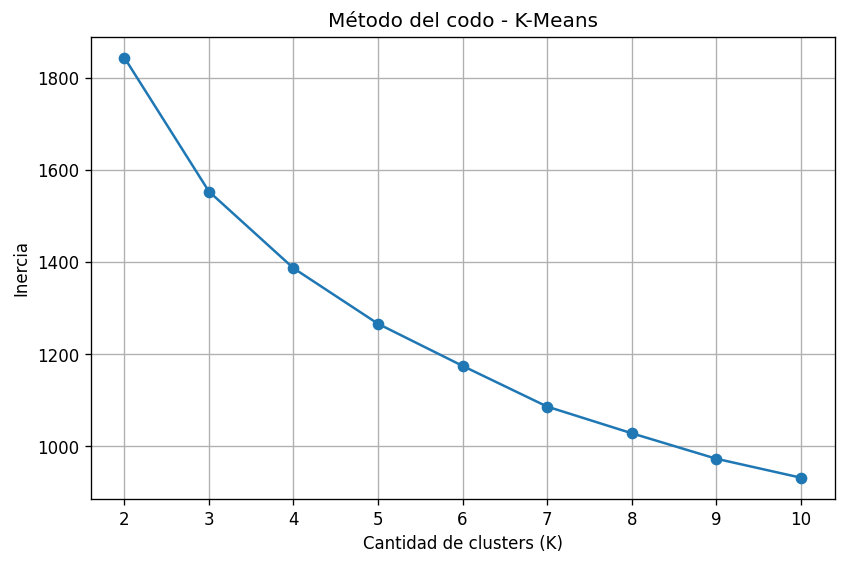

In [12]:
# Gráfico del método del codo

plt.figure(figsize=(8, 5))

plt.plot(
    resultados_df['Cantidad de clusters'],
    resultados_df['Inercia'],
    marker='o'
)

plt.xlabel('Cantidad de clusters (K)')
plt.ylabel('Inercia')
plt.title('Método del codo - K-Means')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### Interpretación del método del codo

En el gráfico se observa que la inercia disminuye a medida que aumenta la cantidad de clusters, lo cual es esperable al incrementar el número de grupos.

La reducción es más pronunciada entre 2 y 4 clusters, mientras que a partir de ese punto la disminución comienza a ser más gradual.

Esto sugiere que una cantidad de entre 3 y 4 clusters podría representar un punto de equilibrio entre la compactación de los grupos y la cantidad de clusters utilizados. Sin embargo, no se observa un punto de codo claramente definido.

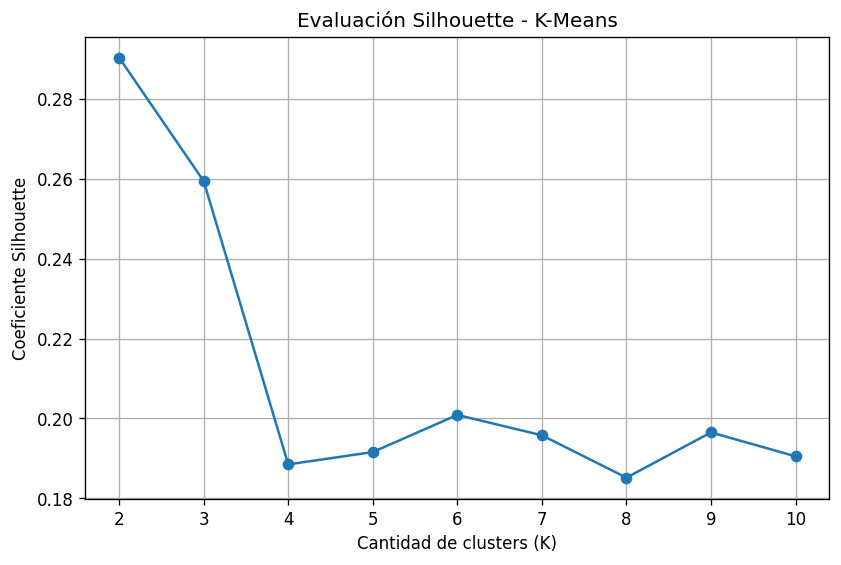

In [13]:
# Gráfico del coeficiente Silhouette

plt.figure(figsize=(8, 5))

plt.plot(
    resultados_df['Cantidad de clusters'],
    resultados_df['Silhouette'],
    marker='o'
)

plt.xlabel('Cantidad de clusters (K)')
plt.ylabel('Coeficiente Silhouette')
plt.title('Evaluación Silhouette - K-Means')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### Interpretación del coeficiente Silhouette

El coeficiente Silhouette alcanza su valor máximo cuando se utilizan 2 clusters, con un resultado de 0.2903.

Al aumentar la cantidad de grupos, el indicador disminuye considerablemente, manteniéndose en valores inferiores para las alternativas restantes.

Esto indica que la división en 2 clusters presenta la mejor separación relativa entre los grupos evaluados. No obstante, el valor obtenido sugiere que la separación entre los clientes no es especialmente marcada.

### Selección de la cantidad de clusters

Considerando los resultados obtenidos mediante ambos métodos, se selecciona inicialmente K=2 para entrenar el modelo definitivo de K-Means.

Esta decisión se fundamenta principalmente en que dicha alternativa presenta el mayor coeficiente Silhouette (0.2903), indicando una mejor separación relativa entre los grupos en comparación con las demás cantidades evaluadas.

Si bien el método del codo no presenta un punto de inflexión claramente definido, la combinación de ambos indicadores permite considerar 2 clusters como una alternativa inicial razonable.

In [14]:
# Entrenar el modelo K-Means definitivo con 2 clusters

kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Asignar cada cliente a un cluster
df_kmeans = df.copy()

df_kmeans['Cluster_KMeans'] = kmeans_final.fit_predict(X_scaled)

# Mostrar los primeros registros con su cluster asignado
df_kmeans.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster_KMeans
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,1


In [15]:
# Contar cuántos clientes quedaron en cada cluster

df_kmeans['Cluster_KMeans'].value_counts().sort_index()

Cluster_KMeans
0    252
1    188
Name: count, dtype: int64

### Análisis de los clusters obtenidos

Una vez entrenado el modelo K-Means, se asignó cada cliente a uno de los dos grupos identificados.

La distribución obtenida fue de 252 clientes en el Cluster 0 y 188 clientes en el Cluster 1.

Para comprender las diferencias entre ambos grupos, se analizarán los gastos promedio en cada categoría de productos, utilizando los valores originales del dataset.

In [16]:
# Calcular el gasto promedio por cluster

perfil_kmeans = df_kmeans.groupby('Cluster_KMeans')[
    variables_gasto
].mean()

perfil_kmeans

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster_KMeans,,,,,,
0,13973.126984,2401.750000,2918.706349,3705.670635,491.944444,1038.043651
1,9355.867021,10346.361702,14697.063830,2222.452128,6084.505319,2177.425532


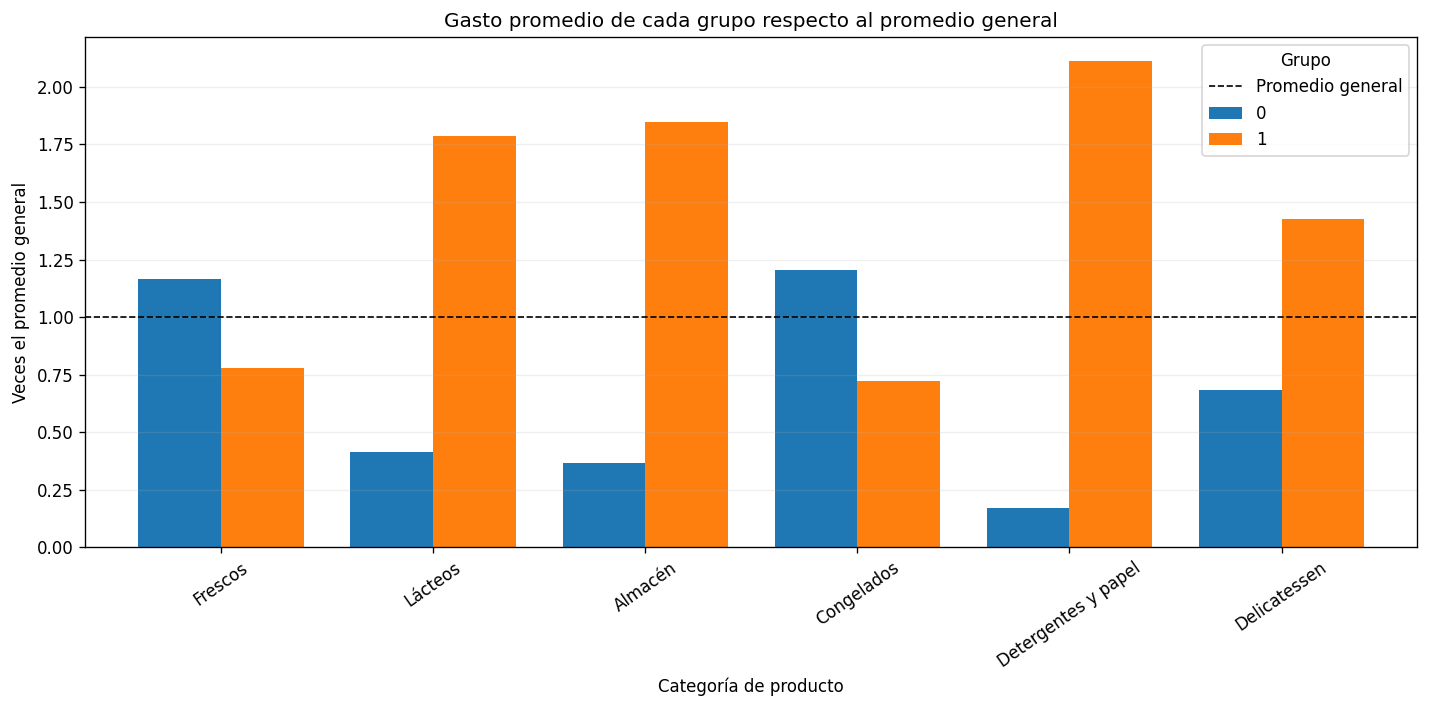

In [17]:
# Comparar el gasto promedio relativo al promedio general
promedio_general = df[variables_gasto].mean()
perfil_relativo_promedios = perfil_kmeans.div(promedio_general)

nombres = ['Frescos', 'Lácteos', 'Almacén', 'Congelados', 'Detergentes y papel', 'Delicatessen']
ax = perfil_relativo_promedios.T.set_axis(nombres).plot(
    kind='bar', figsize=(12, 6), width=0.78
)
ax.axhline(1, color='black', linewidth=1, linestyle='--', label='Promedio general')
ax.set_title('Gasto promedio de cada grupo respecto al promedio general')
ax.set_xlabel('Categoría de producto')
ax.set_ylabel('Veces el promedio general')
ax.tick_params(axis='x', rotation=35)
ax.legend(title='Grupo')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()


### Interpretación de los perfiles identificados mediante K-Means

A partir del análisis de los gastos promedio de cada cluster, se observan diferencias en los patrones de consumo de los clientes.

**Cluster 0: Clientes con mayor orientación hacia productos frescos**

Este grupo presenta un gasto promedio superior en las categorías Fresh y Frozen. En cambio, registra niveles de gasto considerablemente menores en Milk, Grocery y Detergents_Paper.

**Cluster 1: Clientes con mayor orientación hacia productos de almacén y consumo**

Este grupo presenta un gasto promedio significativamente superior en Milk, Grocery y Detergents_Paper. También registra un mayor gasto promedio en Delicassen.

En conjunto, K-Means ofrece una primera segmentación interpretable según los patrones de gasto. Sin embargo, el Silhouette de 0,2903 refleja una separación moderada-baja, por lo que estos grupos deben entenderse como tendencias dentro de la muestra y no como perfiles completamente separados.

## 5. Modelo DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) es un algoritmo de aprendizaje no supervisado que permite identificar grupos de observaciones a partir de la densidad de los datos.

A diferencia de K-Means, DBSCAN no requiere definir previamente la cantidad de clusters. El algoritmo identifica agrupamientos según la proximidad entre las observaciones y permite detectar registros que no pertenecen a ningún grupo, considerados ruido o valores atípicos.

Para su aplicación se deben definir dos parámetros principales:

- **Epsilon (eps):** distancia máxima entre observaciones para considerarlas vecinas.
- **Min_samples:** cantidad mínima de observaciones necesarias para formar una región de alta densidad.

### Selección de parámetros

Para aplicar DBSCAN es necesario establecer los parámetros eps y min_samples.

Como punto de partida, se utilizará un valor de min_samples igual a 12. Para explorar un valor adecuado de eps, se analizarán las distancias de cada observación a sus vecinos más cercanos mediante un gráfico K-distance.

Este análisis permitirá identificar una distancia inicial razonable para aplicar el algoritmo.

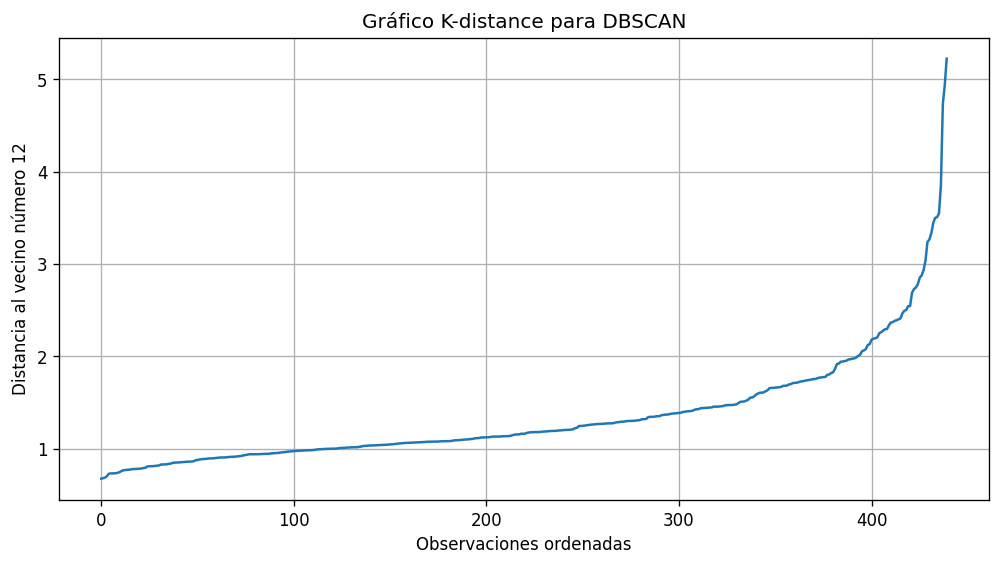

In [18]:
# Importar las herramientas necesarias
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

# Definir el valor inicial de min_samples
min_samples = 12

# Calcular las distancias a los vecinos más cercanos
neighbors = NearestNeighbors(n_neighbors=min_samples)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Ordenar las distancias de menor a mayor
distances_sorted = np.sort(distances[:, -1])

# Graficar las distancias
plt.figure(figsize=(10, 5))

plt.plot(distances_sorted)

plt.xlabel('Observaciones ordenadas')
plt.ylabel('Distancia al vecino número 12')
plt.title('Gráfico K-distance para DBSCAN')

plt.grid(True)
plt.show()

In [19]:
# Aplicar el modelo DBSCAN
dbscan = DBSCAN(eps=2.0, min_samples=12)

# Asignar un cluster a cada observación
clusters_dbscan = dbscan.fit_predict(X_scaled)

# Incorporar los resultados al dataset original
df['Cluster_DBSCAN'] = clusters_dbscan

# Contar cuántas observaciones quedaron en cada grupo
df['Cluster_DBSCAN'].value_counts().sort_index()

Cluster_DBSCAN
-1     17
 0    423
Name: count, dtype: int64

### Análisis de los resultados iniciales de DBSCAN

En una primera aplicación del algoritmo DBSCAN, utilizando los parámetros `eps = 2.0` y `min_samples = 12`, se identificó un único cluster compuesto por 423 observaciones y 17 observaciones clasificadas como ruido.

Esto significa que aproximadamente el 96,1 % de los clientes fueron agrupados en un mismo cluster, mientras que el 3,9 % restante no presentó suficiente densidad de vecinos para ser asignado a dicho grupo.

A partir de estos resultados, se observa que la configuración inicial no permite identificar distintos perfiles de clientes, ya que concentra la gran mayoría de las observaciones en un único grupo.

Por este motivo, se probarán diferentes valores del parámetro `eps`, con el objetivo de analizar si es posible obtener una segmentación más diferenciada.

In [20]:
# Probar diferentes valores de eps
valores_eps = [1.2, 1.4, 1.6, 1.8, 2.0]

for eps in valores_eps:

    modelo = DBSCAN(eps=eps, min_samples=12)

    etiquetas = modelo.fit_predict(X_scaled)

    cantidad_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)

    cantidad_ruido = list(etiquetas).count(-1)

    print(f"eps: {eps} | Clusters: {cantidad_clusters} | Ruido: {cantidad_ruido}")

eps: 1.2 | Clusters: 1 | Ruido: 105
eps: 1.4 | Clusters: 1 | Ruido: 67
eps: 1.6 | Clusters: 1 | Ruido: 42
eps: 1.8 | Clusters: 1 | Ruido: 27
eps: 2.0 | Clusters: 1 | Ruido: 17


### Evaluación de diferentes valores de eps

Con el objetivo de analizar el comportamiento de DBSCAN, se probaron cinco valores diferentes del parámetro eps, manteniendo constante min_samples = 12.

Los resultados muestran que, para todos los valores evaluados, el algoritmo identifica un único cluster. Sin embargo, la cantidad de observaciones clasificadas como ruido disminuye a medida que aumenta eps.

Esto ocurre porque, al incrementar la distancia máxima entre vecinos, más observaciones pueden incorporarse a una región considerada densa.

A pesar de esta variación, ninguna de las configuraciones evaluadas permitió identificar múltiples grupos de clientes. Por lo tanto, hasta el momento, DBSCAN no muestra una capacidad clara para segmentar este conjunto de datos en diferentes perfiles.

## 6. Comparación de resultados

Los dos algoritmos se ajustaron sobre las mismas seis variables de gasto, transformadas con `log1p` y estandarizadas. K-Means asigna cada cliente a uno de los grupos definidos por K. DBSCAN busca regiones densas y puede dejar clientes sin asignar, con la etiqueta `-1`.

La tabla compara K-Means con K = 2 y DBSCAN con `eps = 2.0` y `min_samples = 12`. El porcentaje de ruido se calcula sobre los 440 clientes.

In [21]:
etiquetas_kmeans = df_kmeans["Cluster_KMeans"]
etiquetas_dbscan = df["Cluster_DBSCAN"]
asignados_dbscan = etiquetas_dbscan[etiquetas_dbscan.ne(-1)]
n_ruido = etiquetas_dbscan.eq(-1).sum()

def tamanos_por_grupo(etiquetas):
    return " y ".join(etiquetas.value_counts().sort_index().astype(str))

comparacion = pd.DataFrame({
    "Grupos encontrados": [etiquetas_kmeans.nunique(), asignados_dbscan.nunique()],
    "Clientes por grupo": [
        tamanos_por_grupo(etiquetas_kmeans),
        tamanos_por_grupo(asignados_dbscan),
    ],
    "Clientes marcados como ruido": [0, n_ruido],
    "Ruido (%)": [0.0, round(100 * n_ruido / len(df), 1)],
    "Silhouette": [f"{silhouette_score(X_scaled, etiquetas_kmeans):.4f}", "No aplica"],
}, index=["K-Means", "DBSCAN"])

comparacion

,Grupos encontrados,Clientes por grupo,Clientes marcados como ruido,Ruido (%),Silhouette
K-Means,2,252 y 188,0,0.0,0.2903
DBSCAN,1,423,17,3.9,No aplica


K-Means obtuvo grupos de 252 y 188 clientes y un Silhouette de 0,2903. Fue el valor más alto entre las alternativas de K evaluadas, aunque indica una separación limitada. DBSCAN reunió a 423 clientes en un grupo y marcó a 17 como ruido (3,9 %). El Silhouette de DBSCAN queda sin calcular porque hay un solo grupo entre los clientes asignados.

Con `min_samples = 12` y los cinco valores evaluados de `eps` entre 1,2 y 2,0, DBSCAN siempre produjo un solo grupo. El cambio se reflejó en la cantidad de clientes marcados como ruido, que pasó de 105 a 17.

### Visualización de las asignaciones

Se proyectan los mismos clientes sobre las primeras dos componentes principales de las seis variables preparadas. Los paneles comparten ejes y cada punto mantiene su posición. PCA se usa solo para visualizar las etiquetas de los modelos, que fueron ajustados con las seis variables.

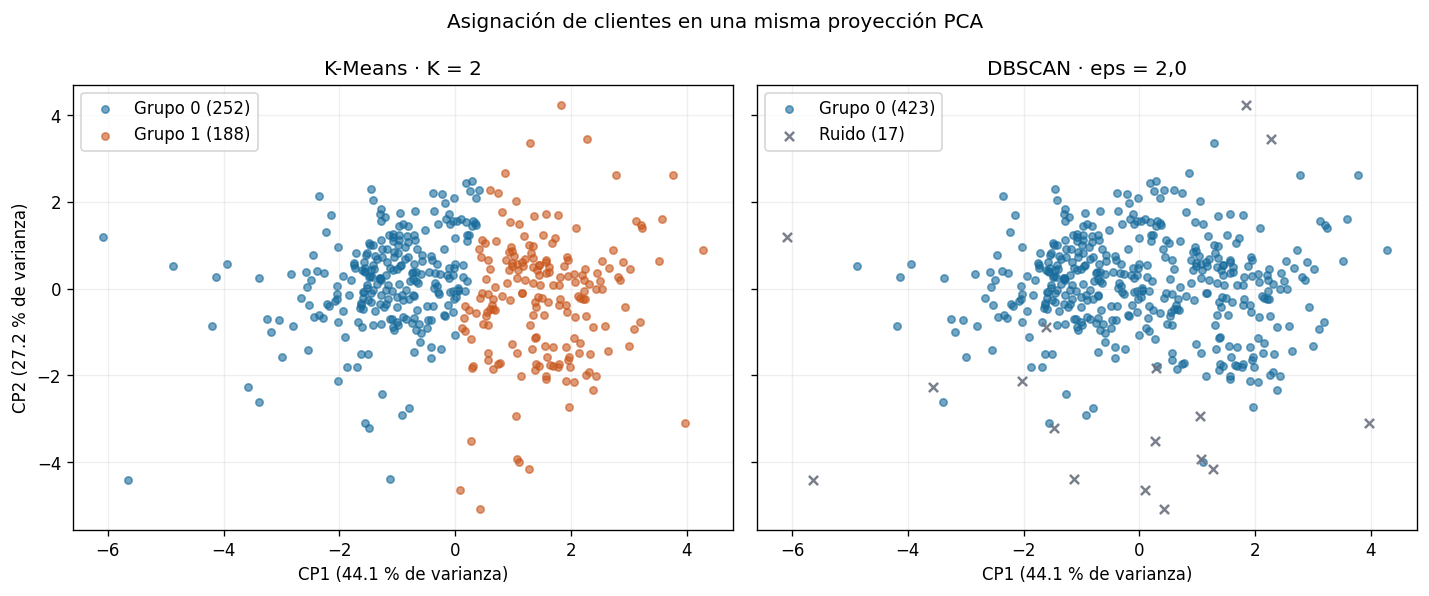

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_scaled)
varianza = 100 * pca.explained_variance_ratio_
colores = {0: "#176b9c", 1: "#c9571c", -1: "#6b7280"}

fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, titulo, etiquetas in [
    (ejes[0], "K-Means · K = 2", etiquetas_kmeans),
    (ejes[1], "DBSCAN · eps = 2,0", etiquetas_dbscan),
]:
    for grupo in sorted(etiquetas.unique(), key=lambda grupo: (grupo == -1, grupo)):
        seleccion = etiquetas.eq(grupo).to_numpy()
        nombre = "Ruido" if grupo == -1 else f"Grupo {grupo}"
        ax.scatter(
            coordenadas[seleccion, 0],
            coordenadas[seleccion, 1],
            s=30 if grupo == -1 else 19,
            alpha=0.9 if grupo == -1 else 0.6,
            marker="x" if grupo == -1 else "o",
            color=colores[grupo],
            label=f"{nombre} ({seleccion.sum()})",
        )
    ax.set_title(titulo)
    ax.set_xlabel(f"CP1 ({varianza[0]:.1f} % de varianza)")
    ax.legend()
    ax.grid(alpha=0.2)

ejes[0].set_ylabel(f"CP2 ({varianza[1]:.1f} % de varianza)")
fig.suptitle("Asignación de clientes en una misma proyección PCA")
fig.tight_layout()
plt.show()

## 7. Identificación de perfiles de clientes

El gráfico anterior muestra la ubicación de los clientes. Para entender qué diferencia a los grupos de K-Means, calculamos las medianas en las unidades monetarias originales. La mediana reduce la influencia de los clientes con gastos extremos. El mapa de calor divide la mediana de cada grupo por la mediana de los 440 clientes en esa misma categoría. Un valor de 1,00 indica que ambas medianas coinciden.

In [23]:
medianas = df_kmeans.groupby("Cluster_KMeans")[variables_gasto].median()
tabla_perfiles = medianas.copy()
tabla_perfiles.insert(0, "Clientes", etiquetas_kmeans.value_counts())
tabla_perfiles.insert(1, "% de clientes", (100 * etiquetas_kmeans.value_counts(normalize=True)).round(1))
tabla_perfiles

,Clientes,% de clientes,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster_KMeans,,,,,,,,
0,252,57.3,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,188,42.7,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


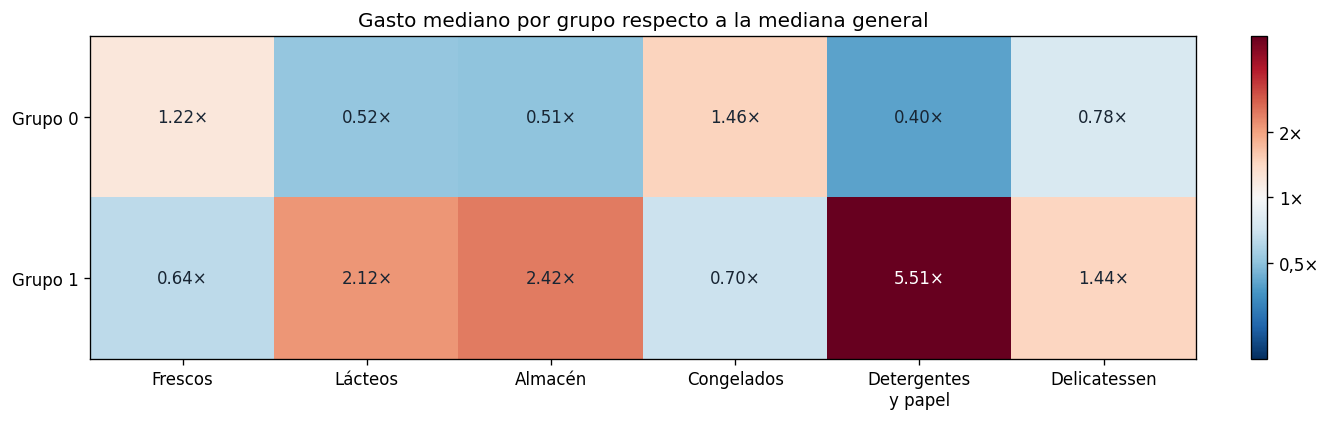

In [24]:
perfil_relativo = medianas.div(df[variables_gasto].median())
# El logaritmo de la razón centra la escala de color en 1× y trata simétricamente
# valores como 0,5× y 2×. Cada celda muestra la razón original.
log_razones = np.log2(perfil_relativo)
limite = np.abs(log_razones.to_numpy()).max()

fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
imagen = ax.imshow(log_razones, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
ax.set_xticks(range(len(variables_gasto)), [
    "Frescos", "Lácteos", "Almacén", "Congelados", "Detergentes\ny papel", "Delicatessen",
])
ax.set_yticks(range(len(medianas)), [f"Grupo {grupo}" for grupo in medianas.index])
for fila, valores in enumerate(perfil_relativo.to_numpy()):
    for columna, razon in enumerate(valores):
        color = "white" if abs(log_razones.iloc[fila, columna]) > 0.65 * limite else "#182533"
        ax.text(columna, fila, f"{razon:.2f}×", ha="center", va="center", color=color)

barra = fig.colorbar(imagen, ax=ax, ticks=[-1, 0, 1])
barra.set_ticklabels(["0,5×", "1×", "2×"])
ax.set_title("Gasto mediano por grupo respecto a la mediana general")
plt.show()

- **Grupo 0 · Frescos y congelados.** Reúne a 252 clientes (57,3 %). La mediana de gasto en frescos es de 10.347,5 unidades monetarias, frente a 5.406,5 en el grupo 1. En congelados es de 2.225 frente a 1.061,5.
- **Grupo 1 · Almacén, lácteos, detergentes y papel.** Reúne a 188 clientes (42,7 %). La mediana de gasto en almacén es de 11.527 unidades monetarias, frente a 2.406 en el grupo 0. En lácteos es de 7.690,5 frente a 1.871 y en detergentes y papel, de 4.495 frente a 327,5. También presenta mayor gasto mediano en delicatessen.

Como referencia adicional, se cruza el grupo con el canal comercial. El canal quedó fuera del ajuste y se usa aquí para describir a los clientes después del agrupamiento.

In [25]:
canal = df_kmeans["Channel"].map({1: "Horeca", 2: "Retail"})
cruce_canal = pd.crosstab(etiquetas_kmeans, canal)
porcentaje_canal = (100 * cruce_canal.div(cruce_canal.sum(axis=1), axis=0)).round(1)

pd.concat({"Clientes": cruce_canal, "% dentro del grupo": porcentaje_canal}, axis=1)

Clientes        % dentro del grupo       
Channel          Horeca Retail             Horeca Retail
Cluster_KMeans                                          
0                   244      8               96.8    3.2
1                    54    134               28.7   71.3

El 96,8 % del grupo 0 pertenece a Horeca (hoteles, restaurantes y cafeterías) y el 71,3 % del grupo 1 pertenece a Retail (comercio minorista). La composición por canal es coherente con los perfiles de gasto. Ambos canales están presentes en los dos grupos.

## 8. Interpretación final

En esta base se pueden identificar **dos perfiles exploratorios de clientes** según su gasto anual. K-Means distingue un grupo con mayor gasto en frescos y congelados y otro con mayor gasto en almacén, lácteos, detergentes y papel. Las diferencias aparecen tanto en los promedios como en las medianas y se relacionan con la composición por canal comercial.

El Silhouette de 0,2903 indica que la separación entre perfiles es limitada. DBSCAN, con los parámetros evaluados, encontró una sola región densa y un conjunto de clientes marcados como ruido. Por eso, la evidencia favorece usar los perfiles de K-Means como una descripción de tendencias de gasto dentro de esta muestra. La comparación con DBSCAN aporta evidencia limitada sobre la estabilidad de esa división frente a otros métodos de agrupamiento.

**Fuente de datos.** Cardoso, M. (2013). *Wholesale customers*. UCI Machine Learning Repository. [DOI 10.24432/C5030X](https://doi.org/10.24432/C5030X).